# KIBA GAT + CNN Drug–Target Affinity Prediction

This notebook evaluates a **GAT + CNN** model on the KIBA drug–target affinity dataset.

The drug is represented as a molecular graph and encoded using a Graph Attention Network (GAT).  
The protein is represented as an amino-acid sequence and encoded using a one-dimensional CNN.

Three evaluation settings are used:

- Random split
- Cold-drug split
- Cold-target split

The same model architecture and training settings are used for all three experiments so that the effect of the data split can be compared fairly.

KIBA affinity scores are used directly as the regression target; they are not converted to pKd.


The GAT drug encoder uses multi-head graph attention to learn different importance weights for neighbouring atoms. The protein CNN and final prediction head remain the same as in the other baseline models.

## Notebook workflow

```text
Raw KIBA dataset
        │
        ▼
Load drugs, proteins and affinity matrix
        │
        ▼
Keep valid KIBA affinity scores
        │
        ├───────────────────────────────┐
        ▼                               ▼
SMILES                              Protein sequence
        │                               │
        ▼                               ▼
RDKit molecular graph              Integer encoding
        │                               │
        ▼                               ▼
GAT drug encoder                   1D CNN protein encoder
        └───────────────┬───────────────┘
                        ▼
                Combined representation
                        │
                        ▼
                 Affinity prediction
                        │
        ┌───────────────┼────────────────┐
        ▼               ▼                ▼
   Random split     Cold-drug        Cold-target
        │               │                │
        ▼               ▼                ▼
 Train / validate / test with early stopping
        │               │                │
        └───────────────┼────────────────┘
                        ▼
            MSE, RMSE, MAE, CI, Pearson
                        │
                        ▼
         Save checkpoints, predictions,
              figures and metrics
                        │
                        ▼
             Compare the three splits
```

The notebook starts from the raw KIBA files and finishes by saving a single model-level metrics table for later comparison with GCN and GIN.


In [1]:
# ============================================================
# COLAB SETUP — DRIVE + GITHUB + PERMANENT RESULTS
# ============================================================

from google.colab import drive, userdata
from pathlib import Path

import base64
import os
import shutil
import subprocess
import torch


# ------------------------------------------------------------
# 1. Mount Google Drive
# ------------------------------------------------------------

drive.mount(
    "/content/drive",
    force_remount=False,
)


# ------------------------------------------------------------
# 2. Project settings
# ------------------------------------------------------------

GITHUB_REPO = (
    "https://github.com/"
    "Thebluesky303/"
    "msc-dissertation-drug-repurposing.git"
)

BRANCH = "final-aml-gnn-dta"

REPO_DIR = Path(
    "/content/final-msc-dissertation-drug-repurposing"
)

DRIVE_PROJECT = Path(
    "/content/drive/MyDrive/"
    "final-msc-dissertation-drug-repurposing"
)

DRIVE_RESULTS = (
    DRIVE_PROJECT / "results"
)


# ------------------------------------------------------------
# 3. Create permanent Drive folders
# ------------------------------------------------------------

result_folders = [
    "metrics",
    "predictions",
    "figures",
    "checkpoints",
    "esm_embeddings",
    "validation",
    "validation_cache",
]

DRIVE_PROJECT.mkdir(
    parents=True,
    exist_ok=True,
)

DRIVE_RESULTS.mkdir(
    parents=True,
    exist_ok=True,
)

for folder_name in result_folders:
    (
        DRIVE_RESULTS / folder_name
    ).mkdir(
        parents=True,
        exist_ok=True,
    )


# ------------------------------------------------------------
# 4. Read GitHub token from Colab Secrets
# ------------------------------------------------------------

token = userdata.get(
    "colab-dissertation"
)

if not token:
    raise ValueError(
        "GITHUB_TOKEN was not found in Colab Secrets."
    )

auth = base64.b64encode(
    f"x-access-token:{token}".encode()
).decode()

git_auth = (
    f"AUTHORIZATION: basic {auth}"
)


# ------------------------------------------------------------
# 5. Clone repository if it does not exist
#    Otherwise update the existing clone
# ------------------------------------------------------------

if not (
    REPO_DIR / ".git"
).exists():

    print(
        "Cloning repository..."
    )

    subprocess.run(
        [
            "git",
            "-c",
            f"http.extraheader={git_auth}",
            "clone",
            "--branch",
            BRANCH,
            "--single-branch",
            GITHUB_REPO,
            str(REPO_DIR),
        ],
        check=True,
    )

else:

    print(
        "Repository already exists."
    )

    subprocess.run(
        [
            "git",
            "-C",
            str(REPO_DIR),
            "-c",
            f"http.extraheader={git_auth}",
            "fetch",
            "origin",
            BRANCH,
        ],
        check=True,
    )

    subprocess.run(
        [
            "git",
            "-C",
            str(REPO_DIR),
            "switch",
            BRANCH,
        ],
        check=True,
    )

    subprocess.run(
        [
            "git",
            "-C",
            str(REPO_DIR),
            "-c",
            f"http.extraheader={git_auth}",
            "pull",
            "--ff-only",
            "origin",
            BRANCH,
        ],
        check=True,
    )


# ------------------------------------------------------------
# 6. Connect repo/results directly to Google Drive
# ------------------------------------------------------------

LOCAL_RESULTS = (
    REPO_DIR / "results"
)

if LOCAL_RESULTS.is_symlink():

    current_target = (
        LOCAL_RESULTS.resolve()
    )

    if current_target != (
        DRIVE_RESULTS.resolve()
    ):
        LOCAL_RESULTS.unlink()

elif LOCAL_RESULTS.exists():

    # Copy any existing local results before replacing
    # the folder with the Drive link.
    for item in LOCAL_RESULTS.iterdir():

        destination = (
            DRIVE_RESULTS
            / item.name
        )

        if item.is_dir():

            shutil.copytree(
                item,
                destination,
                dirs_exist_ok=True,
            )

        else:

            shutil.copy2(
                item,
                destination,
            )

    shutil.rmtree(
        LOCAL_RESULTS
    )


if not LOCAL_RESULTS.exists():

    os.symlink(
        DRIVE_RESULTS,
        LOCAL_RESULTS,
        target_is_directory=True,
    )


# ------------------------------------------------------------
# 7. Move into repository
# ------------------------------------------------------------

os.chdir(
    REPO_DIR
)


# ------------------------------------------------------------
# 8. Final checks
# ------------------------------------------------------------

branch = subprocess.check_output(
    [
        "git",
        "branch",
        "--show-current",
    ],
    text=True,
).strip()

commit = subprocess.check_output(
    [
        "git",
        "log",
        "-1",
        "--oneline",
    ],
    text=True,
).strip()


print()
print("=" * 65)
print("COLAB PROJECT READY")
print("=" * 65)

print(
    "Repository:",
    REPO_DIR,
)

print(
    "Branch:",
    branch,
)

print(
    "Commit:",
    commit,
)

print(
    "Results saved to Drive:",
    LOCAL_RESULTS.resolve(),
)

print(
    "CUDA available:",
    torch.cuda.is_available(),
)

if torch.cuda.is_available():

    print(
        "GPU:",
        torch.cuda.get_device_name(0),
    )

print("=" * 65)


# Install project dependencies for this Colab runtime

%cd /content/final-msc-dissertation-drug-repurposing

!pip install -q -r requirements.txt

print("Project requirements installed.")

import torch
import torch_geometric
import rdkit
import transformers
import pandas
import numpy

print("PyTorch:", torch.__version__)
print("PyG:", torch_geometric.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("Environment ready.")

Mounted at /content/drive
Cloning repository...

COLAB PROJECT READY
Repository: /content/final-msc-dissertation-drug-repurposing
Branch: final-aml-gnn-dta
Commit: 83bcfb6 davis gin cnn model trained.
Results saved to Drive: /content/drive/MyDrive/final-msc-dissertation-drug-repurposing/results
CUDA available: True
GPU: NVIDIA A100-SXM4-40GB
/content
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.4/64.4 kB 6.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 77.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 37.4/37.4 MB 71.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.2/17.2 MB 122.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 134.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 915.3/915.3 kB 70.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 77.5/77.5 kB 10.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 59.8/59.8 kB 6.7 MB/s eta 0:00:00
Project require

# Part A — Setup and data preparation

## 1. Imports

In [2]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
import torch
from IPython.display import display
from rdkit import Chem
from rdkit.Chem import Draw
from torch_geometric.loader import DataLoader

## 2. Locate the project folder

The notebook expects the project to contain `config.py`, `src/`, `data/`, and `results/`.
The code below works when the notebook is run from the project folder, from the `notebooks/` folder, or from a typical Google Colab clone.

In [3]:
def find_project_root() -> Path:
    candidates = [
        Path.cwd(),
        Path.cwd().parent,
        Path("/content/final_aml_gnn_dta"),
    ]

    content_dir = Path("/content")
    if content_dir.exists():
        candidates.extend(path.parent for path in content_dir.glob("*/config.py"))
        candidates.extend(path.parent for path in content_dir.glob("*/final_aml_gnn_dta/config.py"))

    for candidate in candidates:
        if (
            (candidate / "config.py").exists()
            and (candidate / "src").exists()
        ):
            return candidate.resolve()

    raise FileNotFoundError(
        "Project root could not be found. "
        "Open the notebook from final_aml_gnn_dta or clone/copy the project into the current environment."
    )


PROJECT_ROOT = find_project_root()

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print("Project root:", PROJECT_ROOT)

Project root: /content/final-msc-dissertation-drug-repurposing


## 3. Project settings and shared functions

In [4]:
from config import (
    BATCH_SIZE,
    CHECKPOINTS_DIR,
    KIBA_DIR,
    FIGURES_DIR,
    LEARNING_RATE,
    MAX_EPOCHS,
    METRICS_DIR,
    PREDICTIONS_DIR,
    RANDOM_SEED,
    TRAIN_RATIO,
    VALIDATION_RATIO,
    TEST_RATIO,
)

from src.models import GATCNN, count_trainable_parameters
from src.preprocessing import (
    ATOM_FEATURE_DIM,
    BOND_FEATURE_DIM,
    InteractionDataset,
    build_drug_graph_cache,
    build_protein_tensor_cache,
    check_cold_split,
    cold_drug_split,
    cold_target_split,
    load_deepdta_dataset,
    random_split,
)
from src.training import evaluate_model, fit_model
from src.utils import (
    get_device,
    save_predictions_csv,
    set_seed,
)

set_seed(RANDOM_SEED)
device = get_device()

print("Device:", device)
print("Random seed:", RANDOM_SEED)
print("Batch size:", BATCH_SIZE)
print("Maximum epochs:", MAX_EPOCHS)
print("Learning rate:", LEARNING_RATE)

Device: cuda
Random seed: 42
Batch size: 64
Maximum epochs: 200
Learning rate: 0.001


## 4. Load the KIBA dataset

The standard KIBA files are expected in:

```text
data/raw/kiba/
├── ligands_can.txt
├── proteins.txt
└── Y
```

KIBA affinity scores are used directly as the prediction target.  
Unlike DAVIS, no pKd transformation is applied.


In [5]:
kiba_df = load_deepdta_dataset(
    dataset_dir=KIBA_DIR,
    dataset_name="kiba",
    transform_davis=False,
)

print("Number of interactions:", len(kiba_df))
print("Unique drugs:", kiba_df["drug_id"].nunique())
print("Unique targets:", kiba_df["target_id"].nunique())
print(
    "KIBA score range:",
    f'{kiba_df["affinity"].min():.3f}',
    "to",
    f'{kiba_df["affinity"].max():.3f}',
)

display(kiba_df.head())


Number of interactions: 118254
Unique drugs: 2111
Unique targets: 229
KIBA score range: 0.000 to 17.200


,drug_id,target_id,smiles,protein_sequence,affinity
0,CHEMBL1087421,O00141,COC1=C(C=C2C(=C1)CCN=C2C3=CC(=C(C=C3)Cl)Cl)Cl,MTVKTEAAKGTLTYSRMRGMVAILIAFMKQRRMGLNDFIQKIANNS...,11.1
1,CHEMBL1087421,O14920,COC1=C(C=C2C(=C1)CCN=C2C3=CC(=C(C=C3)Cl)Cl)Cl,MSWSPSLTTQTCGAWEMKERLGTGGFGNVIRWHNQETGEQIAIKQC...,11.1
2,CHEMBL1087421,O15111,COC1=C(C=C2C(=C1)CCN=C2C3=CC(=C(C=C3)Cl)Cl)Cl,MERPPGLRPGAGGPWEMRERLGTGGFGNVCLYQHRELDLKIAIKSC...,11.1
3,CHEMBL1087421,P00533,COC1=C(C=C2C(=C1)CCN=C2C3=CC(=C(C=C3)Cl)Cl)Cl,MRPSGTAGAALLALLAALCPASRALEEKKVCQGTSNKLTQLGTFED...,11.1
4,CHEMBL1087421,P04626,COC1=C(C=C2C(=C1)CCN=C2C3=CC(=C(C=C3)Cl)Cl)Cl,MELAALCRWGLLLALLPPGAASTQVCTGTDMKLRLPASPETHLDML...,11.1


## 5. Inspect the dataset

In [18]:
dataset_summary = pd.DataFrame(
    {
        "measure": [
            "Interactions",
            "Unique drugs",
            "Unique targets",
            "Minimum KIBA score",
            "Mean KIBA score",
            "Maximum KIBA score",
        ],
        "value": [
            len(kiba_df),
            kiba_df["drug_id"].nunique(),
            kiba_df["target_id"].nunique(),
            kiba_df["affinity"].min(),
            kiba_df["affinity"].mean(),
            kiba_df["affinity"].max(),
        ],
    }
)

display(dataset_summary)

,measure,value
0,Interactions,118254.000000
1,Unique drugs,2111.000000
2,Unique targets,229.000000
3,Minimum KIBA score,0.000000
4,Mean KIBA score,11.719935
5,Maximum KIBA score,17.200179


## 6. Prepare drug molecular graphs and protein sequences

Each unique drug is converted once into an RDKit/PyTorch Geometric molecular graph and cached.

Each unique protein sequence is also encoded once and cached. Reusing these representations avoids repeating the same preprocessing for every interaction pair.

In [7]:
drug_graph_cache = build_drug_graph_cache(kiba_df)
protein_tensor_cache = build_protein_tensor_cache(kiba_df)

print("Cached drug graphs:", len(drug_graph_cache))
print("Cached protein sequences:", len(protein_tensor_cache))
print("Atom feature dimension:", ATOM_FEATURE_DIM)
print("Bond feature dimension:", BOND_FEATURE_DIM)

Cached drug graphs: 2111
Cached protein sequences: 229
Atom feature dimension: 9
Bond feature dimension: 6


## 7. Inspect one molecular graph

Drug ID: CHEMBL1929238
SMILES: CC(C)(C)C1=CC(=C(S1)NC(=O)NC2=C(C(=CC=C2)Cl)Cl)C(=O)N3CCC(=O)N(CC3)CCN(C)C
Number of atoms: 36
Directed graph edges: 76
Node feature shape: (36, 9)
Bond feature shape: (76, 6)


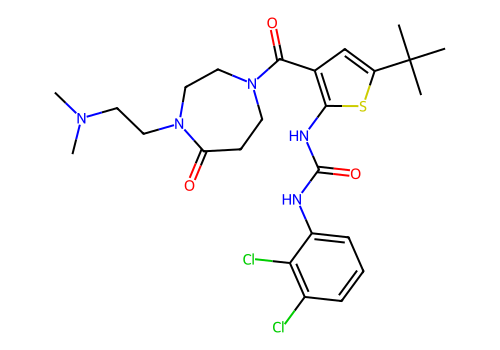

In [8]:
example_row = kiba_df.iloc[330]
example_drug_id = str(example_row["drug_id"])
example_smiles = example_row["smiles"]
example_graph = drug_graph_cache[example_drug_id]

print("Drug ID:", example_drug_id)
print("SMILES:", example_smiles)
print("Number of atoms:", example_graph.num_nodes)
print("Directed graph edges:", example_graph.edge_index.shape[1])
print("Node feature shape:", tuple(example_graph.x.shape))
print("Bond feature shape:", tuple(example_graph.edge_attr.shape))

molecule = Chem.MolFromSmiles(example_smiles)
display(Draw.MolToImage(molecule, size=(500, 350)))

## 8. Helper functions used by the three experiments

The functions below only organise repeated notebook steps.  
Each split still creates a **fresh GAT + CNN model** and is trained independently.

In [9]:
def create_loaders(train_df, validation_df, test_df):
    train_dataset = InteractionDataset(
        train_df,
        drug_graph_cache,
        protein_tensor_cache,
    )
    validation_dataset = InteractionDataset(
        validation_df,
        drug_graph_cache,
        protein_tensor_cache,
    )
    test_dataset = InteractionDataset(
        test_df,
        drug_graph_cache,
        protein_tensor_cache,
    )

    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
    )
    validation_loader = DataLoader(
        validation_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
    )
    test_loader = DataLoader(
        test_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
    )

    return train_loader, validation_loader, test_loader


def print_split_summary(train_df, validation_df, test_df):
    summary = pd.DataFrame(
        {
            "partition": ["Train", "Validation", "Test"],
            "interactions": [
                len(train_df),
                len(validation_df),
                len(test_df),
            ],
            "unique_drugs": [
                train_df["drug_id"].nunique(),
                validation_df["drug_id"].nunique(),
                test_df["drug_id"].nunique(),
            ],
            "unique_targets": [
                train_df["target_id"].nunique(),
                validation_df["target_id"].nunique(),
                test_df["target_id"].nunique(),
            ],
        }
    )

    display(summary)


def plot_training_history(history, split_name):
    history_df = pd.DataFrame(history)

    plt.figure(figsize=(8, 5))
    plt.plot(
        history_df["epoch"],
        history_df["train_loss"],
        label="Training MSE",
    )
    plt.plot(
        history_df["epoch"],
        history_df["validation_loss"],
        label="Validation MSE",
    )
    plt.xlabel("Epoch")
    plt.ylabel("MSE")
    plt.title(f"KIBA GAT + CNN — {split_name}")
    plt.legend()
    plt.tight_layout()

    figure_path = (
        FIGURES_DIR
        / f"kiba_gat_cnn_{split_name}_training.png"
    )
    plt.savefig(figure_path, dpi=200, bbox_inches="tight")
    plt.show()

    return history_df


def run_gat_experiment(
    split_name,
    train_df,
    validation_df,
    test_df,
):
    print(f"Running split: {split_name}")
    print("-" * 60)

    train_loader, validation_loader, test_loader = create_loaders(
        train_df,
        validation_df,
        test_df,
    )

    model = GATCNN()
    trainable_parameters = count_trainable_parameters(model)

    print("Trainable parameters:", f"{trainable_parameters:,}")

    checkpoint_path = (
        CHECKPOINTS_DIR
        / f"kiba_gat_cnn_{split_name}.pt"
    )

    training_result = fit_model(
        model=model,
        train_loader=train_loader,
        validation_loader=validation_loader,
        device=device,
        checkpoint_path=checkpoint_path,
        max_epochs=MAX_EPOCHS,
        learning_rate=LEARNING_RATE,
    )

    history_df = plot_training_history(
        training_result["history"],
        split_name,
    )

    test_result = evaluate_model(
        model=model,
        data_loader=test_loader,
        device=device,
    )

    metrics = test_result["metrics"]

    predictions_df = test_df.copy()
    predictions_df["true_affinity"] = test_result["y_true"]
    predictions_df["predicted_affinity"] = test_result["y_pred"]
    predictions_df["prediction_error"] = (
        predictions_df["predicted_affinity"]
        - predictions_df["true_affinity"]
    )

    prediction_path = (
        PREDICTIONS_DIR
        / f"kiba_gat_cnn_{split_name}.csv"
    )

    save_predictions_csv(
        predictions_df,
        prediction_path,
    )

    result_row = {
        "dataset": "KIBA",
        "model": "GAT + CNN",
        "split": split_name,
        "best_epoch": training_result["best_epoch"],
        "completed_epochs": training_result["completed_epochs"],
        "best_validation_mse": training_result[
            "best_validation_mse"
        ],
        "test_mse": metrics["mse"],
        "test_rmse": metrics["rmse"],
        "test_mae": metrics["mae"],
        "ci": metrics["ci"],
        "pearson": metrics["pearson"],
        "trainable_parameters": trainable_parameters,
    }

    print()
    print("Best epoch:", result_row["best_epoch"])
    print(
        "Best validation MSE:",
        f'{result_row["best_validation_mse"]:.4f}',
    )
    print("Test MSE:", f'{result_row["test_mse"]:.4f}')
    print("Test RMSE:", f'{result_row["test_rmse"]:.4f}')
    print("Test MAE:", f'{result_row["test_mae"]:.4f}')
    print("Concordance index:", f'{result_row["ci"]:.4f}')
    print("Pearson correlation:", f'{result_row["pearson"]:.4f}')

    return {
        "model": model,
        "result": result_row,
        "history": history_df,
        "predictions": predictions_df,
        "checkpoint_path": checkpoint_path,
        "prediction_path": prediction_path,
    }

# Part B — Random split experiment

In the random split, interaction pairs are divided randomly into training, validation, and test sets.  
A drug or protein may therefore appear in more than one partition.

This setting measures performance when the model is evaluated on unseen **interaction pairs**, but not necessarily unseen drugs or proteins.

## 9. Create the random split

In [10]:
random_train_df, random_validation_df, random_test_df = random_split(
    kiba_df,
    train_ratio=TRAIN_RATIO,
    validation_ratio=VALIDATION_RATIO,
    test_ratio=TEST_RATIO,
    seed=RANDOM_SEED,
)

print_split_summary(
    random_train_df,
    random_validation_df,
    random_test_df,
)

random_drug_overlap = (
    set(random_train_df["drug_id"])
    & set(random_test_df["drug_id"])
)

random_target_overlap = (
    set(random_train_df["target_id"])
    & set(random_test_df["target_id"])
)

print(
    "Train-test drug overlap:",
    len(random_drug_overlap),
)
print(
    "Train-test target overlap:",
    len(random_target_overlap),
)

,partition,interactions,unique_drugs,unique_targets
0,Train,94603,2111,229
1,Validation,11825,1868,225
2,Test,11826,1877,221


Train-test drug overlap: 1877
Train-test target overlap: 221


## 10. Train and evaluate GAT + CNN on the random split

Running split: random
------------------------------------------------------------
Trainable parameters: 384,897
Epoch 001 | Train MSE: 2.8521 | Validation MSE: 2.4865
Epoch 002 | Train MSE: 2.1566 | Validation MSE: 1.0026
Epoch 003 | Train MSE: 1.9627 | Validation MSE: 1.2725
Epoch 004 | Train MSE: 1.7553 | Validation MSE: 0.6324
Epoch 005 | Train MSE: 1.5175 | Validation MSE: 0.6823
Epoch 006 | Train MSE: 1.2975 | Validation MSE: 0.6433
Epoch 007 | Train MSE: 1.1684 | Validation MSE: 0.5957
Epoch 008 | Train MSE: 1.0871 | Validation MSE: 0.6218
Epoch 009 | Train MSE: 1.0245 | Validation MSE: 0.5746
Epoch 010 | Train MSE: 0.9673 | Validation MSE: 0.5448
Epoch 011 | Train MSE: 0.9181 | Validation MSE: 0.5384
Epoch 012 | Train MSE: 0.8658 | Validation MSE: 0.5541
Epoch 013 | Train MSE: 0.8105 | Validation MSE: 0.5445
Epoch 014 | Train MSE: 0.7691 | Validation MSE: 0.5020
Epoch 015 | Train MSE: 0.7322 | Validation MSE: 0.4875
Epoch 016 | Train MSE: 0.7048 | Validation MSE: 0.4861
Epoch 0

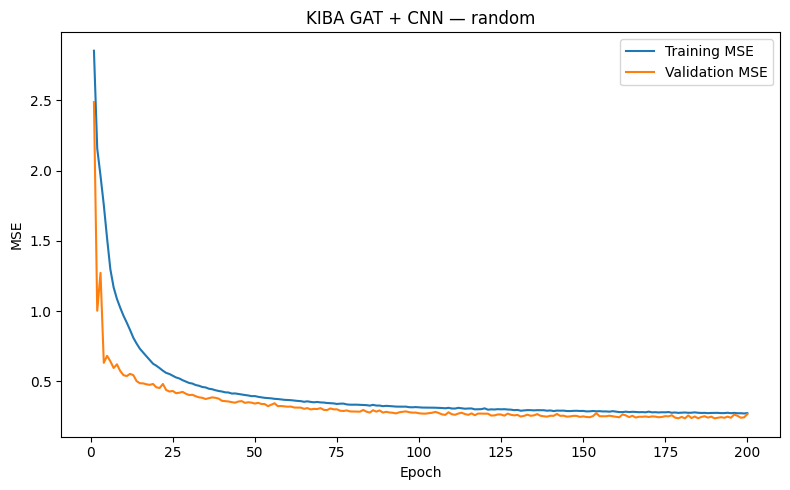


Best epoch: 181
Best validation MSE: 0.2376
Test MSE: 0.2808
Test RMSE: 0.5300
Test MAE: 0.3222
Concordance index: 0.8208
Pearson correlation: 0.7743


In [11]:
random_result = run_gat_experiment(
    split_name="random",
    train_df=random_train_df,
    validation_df=random_validation_df,
    test_df=random_test_df,
)

## 11. Inspect random-split predictions

In [21]:
display(
    random_result["predictions"][
        [
            "drug_id",
            "target_id",
            "true_affinity",
            "predicted_affinity",
            "prediction_error",
        ]
    ].head(10)
)

,drug_id,target_id,true_affinity,predicted_affinity,prediction_error
0,CHEMBL1966722,P35968,11.200000,11.668721,0.468721
1,CHEMBL1970142,P31749,11.200000,11.215884,0.015884
2,CHEMBL1986139,Q05397,11.900001,11.637341,-0.262660
3,CHEMBL1989043,P07333,11.700000,11.985133,0.285133
4,CHEMBL2001920,Q9Y6M4,11.300000,11.471613,0.171613
5,CHEMBL1969126,P53778,11.300000,11.276248,-0.023752
6,CHEMBL1958401,P16591,11.900001,11.968468,0.068467
7,CHEMBL1997129,P49137,11.999998,11.639062,-0.360936
8,CHEMBL1976420,O43781,11.300000,11.316922,0.016922
9,CHEMBL75773,Q04759,11.020819,11.199479,0.178660


# Part C — Cold-drug experiment

In the cold-drug split, drugs are separated between training, validation, and test partitions.

The model is therefore evaluated on **unseen drugs**, while protein targets may have been observed during training. This provides a more demanding assessment of generalisation to new compounds.

## 12. Create and verify the cold-drug split

In [11]:
cold_drug_train_df, cold_drug_validation_df, cold_drug_test_df = cold_drug_split(
    kiba_df,
    train_ratio=TRAIN_RATIO,
    validation_ratio=VALIDATION_RATIO,
    test_ratio=TEST_RATIO,
    seed=RANDOM_SEED,
)

print_split_summary(
    cold_drug_train_df,
    cold_drug_validation_df,
    cold_drug_test_df,
)

cold_drug_is_valid = check_cold_split(
    cold_drug_train_df,
    cold_drug_validation_df,
    cold_drug_test_df,
    column="drug_id",
)

print("No drug overlap:", cold_drug_is_valid)

assert cold_drug_is_valid, "Cold-drug split contains overlapping drugs."

,partition,interactions,unique_drugs,unique_targets
0,Train,94613,1688,229
1,Validation,11479,211,226
2,Test,12162,212,219


No drug overlap: True


## 13. Train and evaluate GAT + CNN on the cold-drug split

Running split: cold_drug
------------------------------------------------------------
Trainable parameters: 384,897
Epoch 001 | Train MSE: 2.8356 | Validation MSE: 2.3198
Epoch 002 | Train MSE: 2.1405 | Validation MSE: 0.7370
Epoch 003 | Train MSE: 1.9467 | Validation MSE: 0.6657
Epoch 004 | Train MSE: 1.7607 | Validation MSE: 0.6056
Epoch 005 | Train MSE: 1.5649 | Validation MSE: 0.6705
Epoch 006 | Train MSE: 1.3291 | Validation MSE: 0.6028
Epoch 007 | Train MSE: 1.1812 | Validation MSE: 0.6016
Epoch 008 | Train MSE: 1.0994 | Validation MSE: 0.5972
Epoch 009 | Train MSE: 1.0356 | Validation MSE: 0.5751
Epoch 010 | Train MSE: 0.9775 | Validation MSE: 0.5707
Epoch 011 | Train MSE: 0.9203 | Validation MSE: 0.5906
Epoch 012 | Train MSE: 0.8733 | Validation MSE: 0.5381
Epoch 013 | Train MSE: 0.8225 | Validation MSE: 0.5378
Epoch 014 | Train MSE: 0.7803 | Validation MSE: 0.5534
Epoch 015 | Train MSE: 0.7393 | Validation MSE: 0.5245
Epoch 016 | Train MSE: 0.7134 | Validation MSE: 0.5294
Epoc

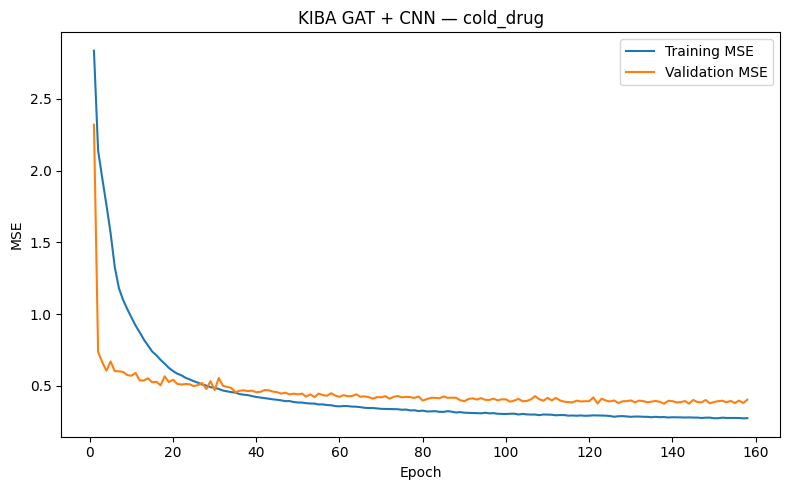


Best epoch: 138
Best validation MSE: 0.3757
Test MSE: 0.3389
Test RMSE: 0.5821
Test MAE: 0.3741
Concordance index: 0.7658
Pearson correlation: 0.7124


In [12]:
cold_drug_result = run_gat_experiment(
    split_name="cold_drug",
    train_df=cold_drug_train_df,
    validation_df=cold_drug_validation_df,
    test_df=cold_drug_test_df,
)

## 14. Inspect cold-drug predictions

In [13]:
display(
    cold_drug_result["predictions"][
        [
            "drug_id",
            "target_id",
            "true_affinity",
            "predicted_affinity",
            "prediction_error",
        ]
    ].head(10)
)

,drug_id,target_id,true_affinity,predicted_affinity,prediction_error
0,CHEMBL1788116,O00141,11.100000,11.193078,0.093078
1,CHEMBL1788116,O14757,11.100000,11.294107,0.194107
2,CHEMBL1788116,O14920,11.100000,11.411049,0.311049
3,CHEMBL1788116,O15530,11.100000,11.425085,0.325085
4,CHEMBL1788116,O75116,11.100000,11.238524,0.138524
5,CHEMBL1788116,O75582,11.100000,11.780977,0.680977
6,CHEMBL1788116,P00533,11.100000,11.659734,0.559733
7,CHEMBL1788116,P04049,12.020819,11.682023,-0.338796
8,CHEMBL1788116,P12931,12.058607,11.665488,-0.393119
9,CHEMBL1788116,P17252,11.100000,11.074934,-0.025066


# Part D — Cold-target experiment

In the cold-target split, protein targets are separated between training, validation, and test partitions.

The model is therefore evaluated on **unseen protein targets**, while drugs may have been observed during training.

## 15. Create and verify the cold-target split

In [14]:
cold_target_train_df, cold_target_validation_df, cold_target_test_df = cold_target_split(
    kiba_df,
    train_ratio=TRAIN_RATIO,
    validation_ratio=VALIDATION_RATIO,
    test_ratio=TEST_RATIO,
    seed=RANDOM_SEED,
)

print_split_summary(
    cold_target_train_df,
    cold_target_validation_df,
    cold_target_test_df,
)

cold_target_is_valid = check_cold_split(
    cold_target_train_df,
    cold_target_validation_df,
    cold_target_test_df,
    column="target_id",
)

print("No target overlap:", cold_target_is_valid)

assert cold_target_is_valid, "Cold-target split contains overlapping targets."

,partition,interactions,unique_drugs,unique_targets
0,Train,94106,2111,183
1,Validation,11870,1606,22
2,Test,12278,1671,24


No target overlap: True


## 16. Train and evaluate GAT + CNN on the cold-target split

Running split: cold_target
------------------------------------------------------------
Trainable parameters: 384,897
Epoch 001 | Train MSE: 2.5728 | Validation MSE: 1.4227
Epoch 002 | Train MSE: 1.9790 | Validation MSE: 1.7876
Epoch 003 | Train MSE: 1.8125 | Validation MSE: 1.3318
Epoch 004 | Train MSE: 1.6538 | Validation MSE: 1.0283
Epoch 005 | Train MSE: 1.4515 | Validation MSE: 0.7055
Epoch 006 | Train MSE: 1.2482 | Validation MSE: 0.8404
Epoch 007 | Train MSE: 1.1162 | Validation MSE: 0.6738
Epoch 008 | Train MSE: 1.0507 | Validation MSE: 0.6435
Epoch 009 | Train MSE: 0.9882 | Validation MSE: 0.6067
Epoch 010 | Train MSE: 0.9392 | Validation MSE: 0.5983
Epoch 011 | Train MSE: 0.8944 | Validation MSE: 0.6153
Epoch 012 | Train MSE: 0.8512 | Validation MSE: 0.5888
Epoch 013 | Train MSE: 0.8075 | Validation MSE: 0.5683
Epoch 014 | Train MSE: 0.7692 | Validation MSE: 0.5605
Epoch 015 | Train MSE: 0.7358 | Validation MSE: 0.5313
Epoch 016 | Train MSE: 0.7003 | Validation MSE: 0.5619
Ep

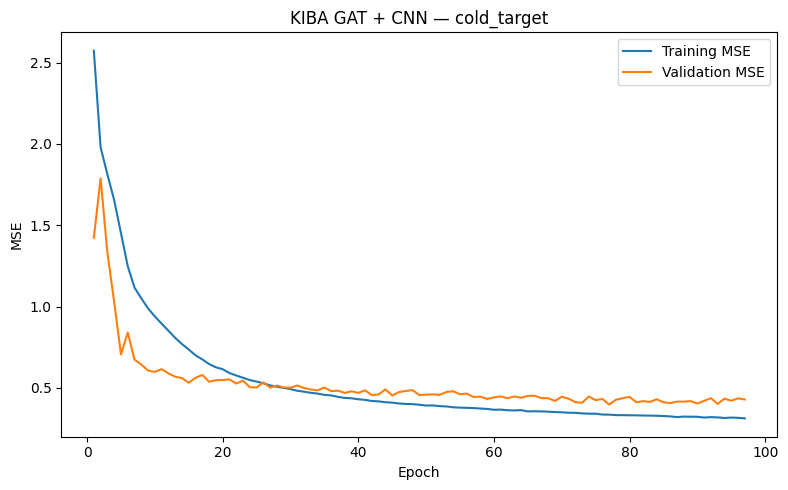


Best epoch: 77
Best validation MSE: 0.3973
Test MSE: 0.4505
Test RMSE: 0.6712
Test MAE: 0.4496
Concordance index: 0.7234
Pearson correlation: 0.6222


In [15]:
cold_target_result = run_gat_experiment(
    split_name="cold_target",
    train_df=cold_target_train_df,
    validation_df=cold_target_validation_df,
    test_df=cold_target_test_df,
)

## 17. Inspect cold-target predictions

In [16]:
display(
    cold_target_result["predictions"][
        [
            "drug_id",
            "target_id",
            "true_affinity",
            "predicted_affinity",
            "prediction_error",
        ]
    ].head(10)
)

,drug_id,target_id,true_affinity,predicted_affinity,prediction_error
0,CHEMBL1087421,P07333,11.100000,11.204150,0.104150
1,CHEMBL1087421,P53779,12.999993,11.257484,-1.742509
2,CHEMBL1088633,P07333,11.100000,11.209746,0.109746
3,CHEMBL1088633,P53779,12.850003,11.267995,-1.582008
4,CHEMBL1090360,O14757,12.116100,11.928917,-0.187183
5,CHEMBL1090360,O15264,12.116100,12.187593,0.071493
6,CHEMBL1090360,P06493,12.116100,11.777486,-0.338614
7,CHEMBL1090360,P07333,12.213943,12.796461,0.582518
8,CHEMBL1090360,P08922,11.800000,12.323031,0.523031
9,CHEMBL1090360,P16591,11.900001,12.762157,0.862157


# Part E — GAT + CNN results summary

The three experiments are now combined into one table.  
This file is the main output used later by the model-comparison notebook.

## 18. Combine and save the metrics

In [23]:
gat_results_df = pd.DataFrame(
    [
        random_result["result"],
        cold_drug_result["result"],
        cold_target_result["result"],
    ]
)

metrics_path = METRICS_DIR / "kiba_gat_cnn.csv"
gat_results_df.to_csv(metrics_path, index=False)

display(gat_results_df.round(4))

print("Metrics saved to:", metrics_path)

,dataset,model,split,test_rmse,test_mse,test_mae,ci,pearson,best_epoch,completed_epochs,best_validation_mse,trainable_parameters
0,KIBA,GAT + CNN,random,0.5300,0.2808,0.3222,0.8208,0.7743,181,200,0.2376,384897
1,KIBA,GAT + CNN,cold_drug,0.5821,0.3389,0.3741,0.7658,0.7124,138,158,0.3757,384897
2,KIBA,GAT + CNN,cold_target,0.6712,0.4505,0.4496,0.7234,0.6222,77,97,0.3973,384897


Metrics saved to: /content/final-msc-dissertation-drug-repurposing/results/metrics/kiba_gat_cnn.csv


## 19. Compare test RMSE across the three splits

Lower RMSE indicates better affinity prediction.
The cold-start results should be interpreted separately from the random split because they represent more difficult generalisation settings.

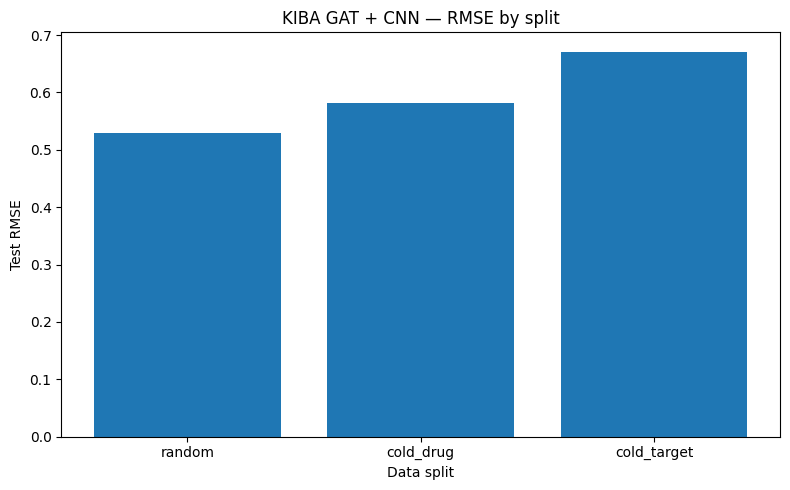

Comparison figure saved to: /content/final-msc-dissertation-drug-repurposing/results/figures/kiba_gat_cnn_split_comparison.png


In [24]:
plt.figure(figsize=(8, 5))
plt.bar(
    gat_results_df["split"],
    gat_results_df["test_rmse"],
)
plt.xlabel("Data split")
plt.ylabel("Test RMSE")
plt.title("KIBA GAT + CNN — RMSE by split")
plt.tight_layout()

comparison_figure_path = (
    FIGURES_DIR
    / "kiba_gat_cnn_split_comparison.png"
)

plt.savefig(
    comparison_figure_path,
    dpi=200,
    bbox_inches="tight",
)
plt.show()

print("Comparison figure saved to:", comparison_figure_path)

## 20. Final experiment summary

In [25]:
summary_columns = [
    "split",
    "best_epoch",
    "best_validation_mse",
    "test_rmse",
    "test_mae",
    "ci",
    "pearson",
]

final_summary = (
    gat_results_df[summary_columns]
    .sort_values("test_rmse")
    .reset_index(drop=True)
)

display(final_summary.round(4))

best_split = final_summary.iloc[0]

print(
    "Lowest test RMSE:",
    best_split["split"],
    f'({best_split["test_rmse"]:.4f})',
)

print()
print("Saved outputs")
print("-" * 50)
print("Metrics:", metrics_path)
print("Random predictions:", random_result["prediction_path"])
print("Cold-drug predictions:", cold_drug_result["prediction_path"])
print("Cold-target predictions:", cold_target_result["prediction_path"])
print("Figures folder:", FIGURES_DIR)
print("Checkpoints folder:", CHECKPOINTS_DIR)

,split,best_epoch,best_validation_mse,test_rmse,test_mae,ci,pearson
0,random,181,0.2376,0.5300,0.3222,0.8208,0.7743
1,cold_drug,138,0.3757,0.5821,0.3741,0.7658,0.7124
2,cold_target,77,0.3973,0.6712,0.4496,0.7234,0.6222


Lowest test RMSE: random (0.5300)

Saved outputs
--------------------------------------------------
Metrics: /content/final-msc-dissertation-drug-repurposing/results/metrics/kiba_gat_cnn.csv
Random predictions: /content/drive/MyDrive/final-msc-dissertation-drug-repurposing/results/predictions/kiba_gat_cnn_random.csv
Cold-drug predictions: /content/final-msc-dissertation-drug-repurposing/results/predictions/kiba_gat_cnn_cold_drug.csv
Cold-target predictions: /content/final-msc-dissertation-drug-repurposing/results/predictions/kiba_gat_cnn_cold_target.csv
Figures folder: /content/final-msc-dissertation-drug-repurposing/results/figures
Checkpoints folder: /content/final-msc-dissertation-drug-repurposing/results/checkpoints


### Notebook completion

This notebook has completed the **KIBA GAT + CNN** baseline under random, cold-drug, and cold-target evaluation.

The saved `kiba_gat_cnn.csv` file can later be combined with the corresponding GCN + CNN and GIN + CNN result files for the final baseline model comparison.